<a href="https://colab.research.google.com/github/cuentacomun548-sketch/clasificacion_sabila_ia/blob/main/notebooks/avance_sabila.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clasificación de sábila con aprendizaje por transferencia
## Avance de proyecto — Inteligencia Artificial (DCI019)

**Autora:** Diana Avila  ·  **Profesor:** Dr. Eduardo Ulises Moya Sánchez
**Código:** https://github.com/[COMPLETAR usuario]/clasificacion_sabila_ia

### Resumen en un minuto

| | |
|---|---|
| **Pregunta** | [COMPLETAR] Ej.: ¿Puede una red preentrenada, ajustada con pocas fotos de sábila, distinguir mis 3 clases con un F1 macro útil, y qué modelo conviene si debe correr en hardware ligero? |
| **Datos** | [COMPLETAR] fotos de sábila en 3 clases (nombre de cada clase, cuántas fotos, cómo se tomaron) |
| **Modelos** | Cuatro redes elegibles desde un panel: MobileNetV3 y MobileNetV4 (escenario portátil), DINOv3 ViT-S y DINOv3 ConvNeXt-T (escenario GPU), todas preentrenadas y ajustadas con la misma receta |
| **Métrica** | F1 macro en validación, elegida antes de ver resultados |
| **Resultado** | [COMPLETAR al final: tabla de la sección 7] |
| **Estado del avance** | Esqueleto completo, partición de datos, línea base y primer entrenamiento |

### Cómo está organizado este cuaderno (el "tablero")

| Sección | Qué muestra |
|---|---|
| 1 | Configuración: **todos los parámetros del experimento en una sola celda** |
| 2 | Datos: lectura, revisión de calidad, duplicados y partición 70/15/15 |
| 3 | Exploración y línea base |
| 4 | Modelo y aprendizaje por transferencia (qué es y cómo se aplica) |
| 5 | Entrenamiento con parada temprana y mejor época |
| 6 | Costo de cómputo de cada modelo |
| 7 | Resultados: tabla, curvas, matriz de confusión y errores |
| 8 | Conclusiones y limitaciones |
| 9 | Evaluación final con el grupo de prueba (se corre una sola vez) |
| 10 | Siguientes pasos (buenas prácticas pendientes) |

**Antes de correr:** en Colab ve a *Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)*.

### ¿Qué es el aprendizaje por transferencia (transfer learning)?

Entrenar una red desde cero necesita muchísimas fotos. En lugar de eso, tomo una red que **ya aprendió a ver** (bordes, texturas, formas) con más de un millón de fotos de ImageNet, le cambio **solo la última capa** para que responda con mis clases y la reentreno con mis fotos. Es como contratar a alguien que ya sabe ver y solo enseñarle el trabajo nuevo.

Lo hago en **dos fases**:

1. **Entrenar solo la cabeza.** Congelo el resto de la red (no cambia) y entreno la capa nueva. Es rápido y estable.
2. **Ajuste fino (fine-tuning).** Descongelo toda la red y la sigo entrenando con una tasa de aprendizaje más pequeña para adaptar los detalles a la sábila.

## 1. Configuración (el tablero de control)

Todo lo que se puede cambiar está en esta celda. **No hay que tocar el código de más abajo** para probar otra receta.

In [1]:
CONFIG = dict(
    # --- Datos ---
    ruta_datos='/content/drive/MyDrive/DATASET_ALOE VERA',      # una carpeta por clase, con sus fotos
    ruta_resultados='/content/drive/MyDrive/proyecto_sabila/resultados',   # aquí se guardan pesos y resultados
    particion=(0.70, 0.15, 0.15),   # entrenamiento / validación / prueba
    semilla_particion=42,           # fija la separación de las fotos (siempre la misma)
    # --- Experimento ---
    modelos=['mobilenet_v3_large', 'mobilenetv4', 'dinov3_vit_s', 'dinov3_convnext_t'],   # las que vienen marcadas en el panel (sección 5)
    semillas=[42],                  # para el reporte final usa [42, 7, 2026] (tres corridas)
    preentrenado=True,              # True = transfer learning con pesos de ImageNet
    # --- Receta de entrenamiento ---
    img_size=224, batch_size=32, num_workers=2,
    epocas_fase1=5, lr_fase1=1e-3,  # fase 1: solo la cabeza
    epocas_fase2=10, lr_fase2=1e-4, # fase 2: ajuste fino de toda la red
    paciencia=4,                    # parada temprana: épocas sin mejorar el F1 de validación
)
CONFIG

{'ruta_datos': '/content/drive/MyDrive/DATASET_ALOE VERA',
 'ruta_resultados': '/content/drive/MyDrive/proyecto_sabila/resultados',
 'particion': (0.7, 0.15, 0.15),
 'semilla_particion': 42,
 'modelos': ['mobilenet_v3_large',
  'mobilenetv4',
  'dinov3_vit_s',
  'dinov3_convnext_t'],
 'semillas': [42],
 'preentrenado': True,
 'img_size': 224,
 'batch_size': 32,
 'num_workers': 2,
 'epocas_fase1': 5,
 'lr_fase1': 0.001,
 'epocas_fase2': 10,
 'lr_fase2': 0.0001,
 'paciencia': 4}

In [2]:
%pip install -q "timm>=1.0.20" ipywidgets

In [3]:
import os, json, time, random, shutil, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
import timm
import ipywidgets as W
from IPython.display import display, clear_output

try:
    from google.colab import drive
    drive.mount('/content/drive')       # Google te pedirá permiso la primera vez
except ImportError:
    print('Fuera de Colab: usa rutas locales en CONFIG')

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
os.makedirs(CONFIG['ruta_resultados'], exist_ok=True)

def fijar_semilla(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

print('PyTorch', torch.__version__, '| Dispositivo:', DEVICE,
      '|', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'SIN GPU (activa la GPU en Colab)')

Mounted at /content/drive
PyTorch 2.14.1+cu130 | Dispositivo: cuda | Tesla T4


## 2. Los datos

Las fotos están en Google Drive, una carpeta por clase (si prefieres no usar Drive, la celda de abajo te deja subir un **.zip** con esa misma estructura):

```
datos.zip
    clase_1/  foto001.jpg ...
    clase_2/  ...
    clase_3/  ...
```

La celda de abajo te pide el archivo la primera vez. Las fotos duran mientras la sesión de Colab esté abierta; los resultados se descargan a tu PC al final (sección 9b).

**Reglas que sigo para que el experimento sea confiable:**

1. **Semilla fija.** La separación de las fotos siempre es la misma.
2. **Separar antes de mirar.** 70 % entrenamiento, 15 % validación, 15 % prueba. La validación sirve para decidir cuándo parar y qué versión guardar; la prueba se guarda intacta para el final.
3. **Fotos casi idénticas van juntas.** Calculo una "huella" de cada foto y mantengo en el mismo grupo las que son iguales, para que el modelo no vea en validación una foto que ya vio al entrenar.
4. **Solo fotos originales.** Si el dataset trae versiones *aumentadas* (giradas, con ruido) de la misma foto, **hay que quitarlas antes de partir**; si no, la validación sale falsamente buena. El aumento se hace después, solo en entrenamiento.
5. **Comparar contra una línea base** y **elegir la métrica antes de ver resultados.**

In [4]:
# Si todavía no hay fotos en Colab, pido el .zip (solo la primera vez de cada sesión)
if not Path(CONFIG['ruta_datos']).exists():
    try:
        from google.colab import files
        print('Sube tu .zip con una carpeta por clase:')
        subido = files.upload()
        shutil.unpack_archive(next(iter(subido)), CONFIG['ruta_datos'])
    except ImportError:
        raise FileNotFoundError(f"No existe {CONFIG['ruta_datos']}")

In [15]:
import hashlib
EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

# Copio las fotos al disco local de Colab si vinieran de Drive (leer de Drive en cada época es muy lento)
origen = Path(CONFIG['ruta_datos'])
if str(origen).startswith('/content/drive'):
    local = Path('/content/datos_local')
    if not local.exists():
        shutil.copytree(origen, local)
    origen = local

# Si el zip traía una carpeta contenedora (datos/clase_1/...), entro hasta las carpetas de clases
raiz = origen
while True:
    subs = [d for d in raiz.iterdir() if d.is_dir() and not d.name.startswith(('.', '__'))]
    if len(subs) == 1 and any(x.is_dir() for x in subs[0].iterdir()):
        raiz = subs[0]
    else:
        break

clases = sorted(d.name for d in raiz.iterdir() if d.is_dir())
assert len(clases) >= 2, f'No encontré carpetas de clases en {raiz}'
clase_a_idx = {c: i for i, c in enumerate(clases)}

filas, corruptas = [], []
for c in clases:
    for p in sorted((raiz / c).rglob('*')):
        if p.suffix.lower() not in EXT:
            continue
        try:
            md5 = hashlib.md5(p.read_bytes()).hexdigest()      # huella exacta del archivo
            with Image.open(p) as im:
                im = im.convert('RGB')
                ancho, alto = im.size
                g = np.asarray(im.convert('L').resize((16, 16)))
                huella = ''.join('1' if v > g.mean() else '0' for v in g.flatten())
            filas.append(dict(ruta=str(p), clase=c, y=clase_a_idx[c], ancho=ancho, alto=alto, huella=huella, md5=md5))
        except Exception:
            corruptas.append(str(p))

df = pd.DataFrame(filas)

# Copias EXACTAS (mismo contenido, p. ej. por una subida doble a Drive): me quedo con una sola de cada una
copias = df.duplicated('md5', keep='first')
print(f'Copias exactas encontradas: {int(copias.sum())} -> eliminadas del análisis (los archivos en Drive no se tocan)')
df = df[~copias].reset_index(drop=True)

df['grupo'] = df.groupby('huella').ngroup()      # fotos con la misma huella = mismo grupo

print('Clases:', clase_a_idx)
print(f'Fotos únicas: {len(df)} | corruptas: {len(corruptas)} | fotos casi idénticas agrupadas: {len(df) - df.grupo.nunique()}')

# --- Partición a nivel de grupo, estratificada por clase, con semilla fija
S = CONFIG['semilla_particion']
p_tr, p_va, p_te = CONFIG['particion']
g = df.groupby('grupo').agg(y=('y', 'first')).reset_index()
g_tr, g_resto = train_test_split(g, test_size=1 - p_tr, stratify=g['y'], random_state=S)
g_va, g_te = train_test_split(g_resto, test_size=p_te / (p_va + p_te), stratify=g_resto['y'], random_state=S)
mapa = {**{k: 'train' for k in g_tr.grupo}, **{k: 'val' for k in g_va.grupo}, **{k: 'test' for k in g_te.grupo}}
df['split'] = df['grupo'].map(mapa)

df.drop(columns=['huella', 'md5']).to_csv(f"{CONFIG['ruta_resultados']}/particion.csv", index=False)
resumen = pd.crosstab(df['clase'], df['split'])[['train', 'val', 'test']]
resumen.loc['TOTAL'] = resumen.sum()
resumen

Copias exactas encontradas: 649 -> eliminadas del análisis (los archivos en Drive no se tocan)
Clases: {'Fresh Aloe Vera': 0, 'Rot Aloe Vera': 1, 'Rust Aloe Vera': 2}
Fotos únicas: 2318 | corruptas: 0 | fotos casi idénticas agrupadas: 0


split,train,val,test
clase,,,
Fresh Aloe Vera,441,94,95
Rot Aloe Vera,586,126,126
Rust Aloe Vera,595,128,127
TOTAL,1622,348,348


## 3. Exploración y línea base

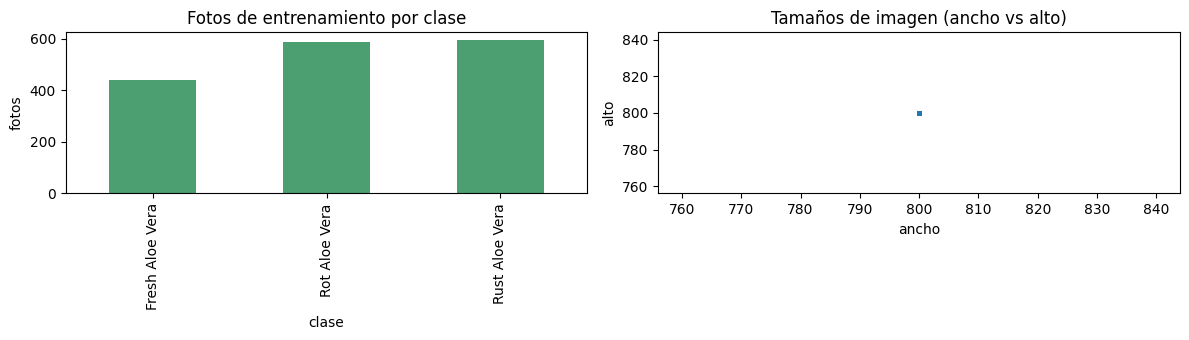

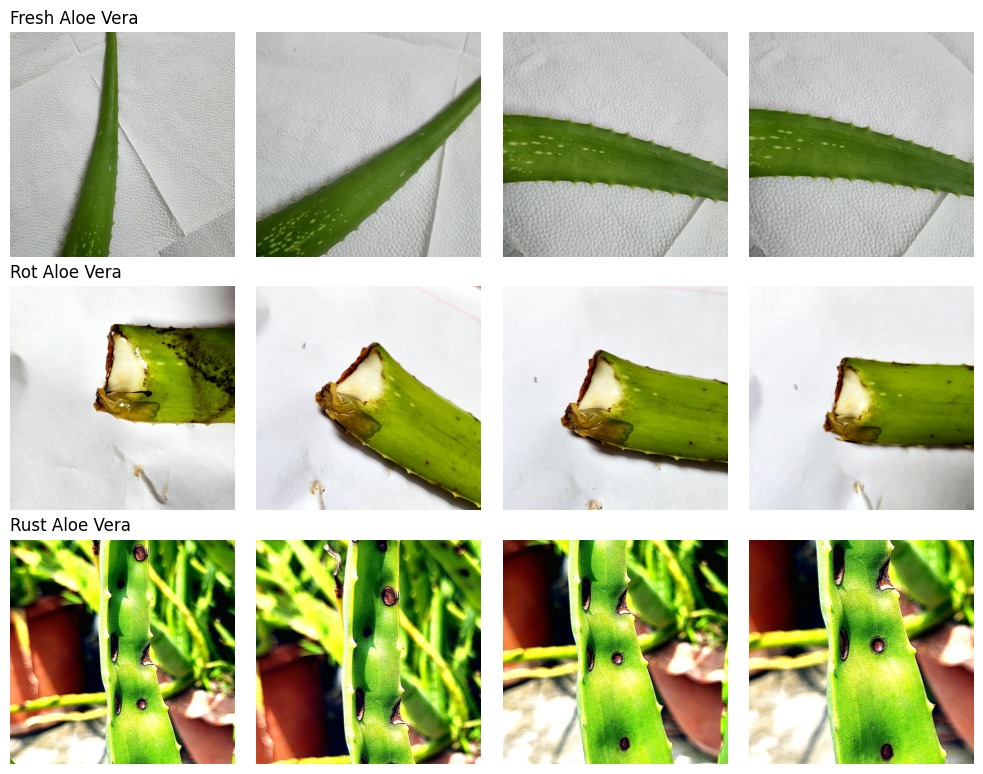

Línea base (siempre "Rust Aloe Vera"): exactitud 0.368 | F1 macro 0.179


In [16]:
tr = df[df.split == 'train']

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
tr['clase'].value_counts().reindex(clases).plot.bar(ax=ax[0], color='#4c9f70')
ax[0].set_title('Fotos de entrenamiento por clase'); ax[0].set_ylabel('fotos')
ax[1].scatter(df.ancho, df.alto, s=6, alpha=.4); ax[1].set_title('Tamaños de imagen (ancho vs alto)')
ax[1].set_xlabel('ancho'); ax[1].set_ylabel('alto')
plt.tight_layout(); plt.show()

# Muestra: 4 fotos por clase
fig, axs = plt.subplots(len(clases), 4, figsize=(10, 2.6 * len(clases)))
for i, c in enumerate(clases):
    for j, ruta in enumerate(tr[tr.clase == c].ruta.head(4)):
        axs[i, j].imshow(Image.open(ruta).convert('RGB')); axs[i, j].axis('off')
        if j == 0: axs[i, j].set_title(c, loc='left')
plt.tight_layout(); plt.show()

# Línea base: un "modelo tonto" que siempre contesta la clase más común
mayoritaria = tr.y.mode()[0]
val = df[df.split == 'val']
base_pred = np.full(len(val), mayoritaria)
BASE_ACC = accuracy_score(val.y, base_pred)
BASE_F1 = f1_score(val.y, base_pred, average='macro', zero_division=0)
print(f'Línea base (siempre "{clases[mayoritaria]}"): exactitud {BASE_ACC:.3f} | F1 macro {BASE_F1:.3f}')

**Cómo leer esto:** la gráfica de barras dice si las clases están balanceadas; los tamaños muestran si hay formatos mezclados; la línea base es el piso: cualquier modelo mío debe superar su F1 macro por mucho.

### Métrica

Uso **F1 macro**: calcula el F1 de cada clase por separado y promedia, de modo que cada clase pesa igual aunque tenga menos fotos. La **exactitud** puede verse bien aunque el modelo ignore una clase pequeña. La elegí **antes** de ver los resultados. También reviso la **matriz de confusión** para saber qué clase se confunde con cuál.

## 4. Las redes y la preparación de los datos

Elegí cuatro redes pensando en la tesis (clasificar enfermedades en agave con dos escenarios: hardware portátil y estación con GPU):

| Red | Familia | Escenario | Por qué |
|---|---|---|---|
| MobileNetV3-Large | CNN | Portátil | Referencia: la generación anterior de las MobileNets |
| MobileNetV4 | CNN | Portátil | La generación más reciente, diseñada para dispositivos móviles |
| DINOv3 ViT-S/16 | Transformer | GPU | Transformer pequeño destilado de un modelo gigante |
| DINOv3 ConvNeXt-Tiny | CNN | GPU | CNN moderna destilada del **mismo** modelo gigante |

Las dos últimas aprendieron del mismo "maestro", así que si una gana, es por la arquitectura y no porque vio más datos: una comparación CNN contra transformer más justa. Todas se ajustan con la **misma receta**; la única diferencia es que las más grandes usan una tasa de aprendizaje de ajuste fino menor (`mult_ft`), porque con tasas altas se desestabilizan.

Si alguna red no se puede descargar, el código usa una de respaldo y lo avisa en pantalla; en ese caso anótalo en tu reporte.

In [17]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # valores de ImageNet
S_IMG = CONFIG['img_size']

# Aumento de datos SOLO en entrenamiento (no uso volteo vertical: ajusta si tus fotos no tienen orientación fija)
tf_train = transforms.Compose([
    transforms.RandomResizedCrop(S_IMG, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
tf_eval = transforms.Compose([
    transforms.Resize(int(S_IMG * 1.14)), transforms.CenterCrop(S_IMG),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class FotosDS(Dataset):
    def __init__(self, d, tf):
        self.rutas, self.y, self.tf = d.ruta.tolist(), d.y.tolist(), tf
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.tf(Image.open(self.rutas[i]).convert('RGB')), self.y[i]

def cargadores(semilla):
    gen = torch.Generator(); gen.manual_seed(semilla)
    def mk(split, tf, mezclar):
        return DataLoader(FotosDS(df[df.split == split], tf), batch_size=CONFIG['batch_size'],
                          shuffle=mezclar, num_workers=CONFIG['num_workers'],
                          generator=gen if mezclar else None, pin_memory=(DEVICE == 'cuda'))
    return mk('train', tf_train, True), mk('val', tf_eval, False), mk('test', tf_eval, False)

ZOO = {
    'mobilenet_v3_large': dict(fuente='torchvision', familia='CNN', escenario='portátil', mult_ft=1.0,
                               nota='referencia, generación anterior'),
    'mobilenetv4': dict(fuente='timm', timm='mobilenetv4_conv_medium', respaldo=['mobilenetv3_large_100'],
                        familia='CNN', escenario='portátil', mult_ft=1.0, nota='CNN móvil más reciente de Google'),
    'dinov3_vit_s': dict(fuente='timm', timm='vit_small_patch16_dinov3.lvd1689m', respaldo=['deit_small_patch16_224'],
                         familia='Transformer', escenario='GPU', mult_ft=0.3, nota='ViT pequeño destilado de DINOv3'),
    'dinov3_convnext_t': dict(fuente='timm', timm='convnext_tiny.dinov3_lvd1689m', respaldo=['convnext_tiny'],
                              familia='CNN', escenario='GPU', mult_ft=0.5, nota='ConvNeXt-Tiny destilada de DINOv3'),
    'resnet50': dict(fuente='torchvision', familia='CNN', escenario='GPU', mult_ft=1.0, nota='clásica (opcional)'),
}

def crear_modelo(nombre, n_clases):
    z = ZOO[nombre]
    if z['fuente'] == 'torchvision':
        pesos = 'DEFAULT' if CONFIG['preentrenado'] else None
        if nombre == 'mobilenet_v3_large':
            m = models.mobilenet_v3_large(weights=pesos)
            m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, n_clases)   # nueva "cabeza"
        else:
            m = models.resnet50(weights=pesos)
            m.fc = nn.Linear(m.fc.in_features, n_clases)
        m.nombre_real = nombre
        return m
    for tn in [z['timm']] + z.get('respaldo', []):
        try:
            m = timm.create_model(tn, pretrained=CONFIG['preentrenado'], num_classes=n_clases)
            if tn != z['timm']:
                print(f"  AVISO: no pude cargar {z['timm']}; usé {tn} en su lugar (anótalo en tu reporte)")
            m.nombre_real = tn
            return m
        except Exception as e:
            print(f"  No pude cargar {tn}: {str(e)[:150]}")
    raise RuntimeError(f'No se pudo crear {nombre}')

def cabeza_de(m, nombre):
    if hasattr(m, 'get_classifier'):          # modelos de timm
        return m.get_classifier()
    return m.classifier[-1] if nombre.startswith('mobilenet_v3') else m.fc

def congelar_base(m, nombre, congelar):
    for p in m.parameters():
        p.requires_grad = not congelar
    for p in cabeza_de(m, nombre).parameters():
        p.requires_grad = True

# Prueba rápida: ¿cargan todas las redes? (también descarga los pesos preentrenados)
for n in CONFIG['modelos']:
    mm = crear_modelo(n, len(clases))
    print(f"{n}: {mm.nombre_real} | {ZOO[n]['familia']} | {ZOO[n]['escenario']} | {sum(p.numel() for p in mm.parameters()) / 1e6:.1f} M parámetros")

mobilenet_v3_large: mobilenet_v3_large | CNN | portátil | 4.2 M parámetros
mobilenetv4: mobilenetv4_conv_medium | CNN | portátil | 8.4 M parámetros
dinov3_vit_s: vit_small_patch16_dinov3.lvd1689m | Transformer | GPU | 21.6 M parámetros
dinov3_convnext_t: convnext_tiny.dinov3_lvd1689m | CNN | GPU | 27.8 M parámetros


## 5. Entrenamiento

Una **época** es una vuelta completa por las fotos de entrenamiento. Al final de cada época califico al modelo con las fotos de **validación**, que nunca usa para aprender.

| Regla | Valor | Por qué |
|---|---|---|
| Fases | 1) solo la cabeza, 2) ajuste fino de toda la red | Primero estabiliza la capa nueva, luego adapta los detalles |
| Parada temprana | Si el F1 de validación no mejora en `paciencia` épocas | Evita seguir cuando ya solo memoriza |
| Mejor modelo | Me quedo con la época de mejor F1 en validación, no con la última | Es la versión que mejor generaliza |
| Misma receta | Igual para todos los modelos | Comparación justa |

Los pesos y resultados de cada corrida se guardan en `CONFIG['ruta_resultados']`; las corridas ya hechas se saltan. Como la sesión de Colab es temporal, **descarga los resultados al terminar** (sección 9b).

In [8]:
@torch.no_grad()
def evaluar(m, dl, crit):
    m.eval(); P, Y, L, n = [], [], 0.0, 0
    for x, y in dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = m(x)
        L += crit(out, y).item() * len(y); n += len(y)
        P += out.argmax(1).cpu().tolist(); Y += y.cpu().tolist()
    return dict(loss=L / n, f1=f1_score(Y, P, average='macro', zero_division=0), acc=accuracy_score(Y, P), y=Y, p=P)

def ms_por_foto(m, dispositivo, repeticiones=30):
    # Tiempo de clasificar UNA foto (batch 1) en 'cpu' o 'cuda'; sirve para comparar redes entre sí
    if dispositivo == 'cuda' and not torch.cuda.is_available():
        return None
    mc = copy.deepcopy(m).to(dispositivo).eval()
    x = torch.randn(1, 3, S_IMG, S_IMG, device=dispositivo)
    with torch.no_grad():
        for _ in range(5):
            mc(x)
        if dispositivo == 'cuda': torch.cuda.synchronize()
        t = time.time()
        for _ in range(repeticiones):
            mc(x)
        if dispositivo == 'cuda': torch.cuda.synchronize()
    return (time.time() - t) / repeticiones * 1000

def entrenar(nombre, semilla):
    fijar_semilla(semilla)
    dl_tr, dl_va, _ = cargadores(semilla)
    m = crear_modelo(nombre, len(clases)).to(DEVICE)
    crit = nn.CrossEntropyLoss()
    usar_amp = (DEVICE == 'cuda')
    scaler = torch.amp.GradScaler('cuda', enabled=usar_amp)
    hist, mejor, ep, t0 = [], dict(f1=-1.0, ep=0, estado=None), 0, time.time()
    lr2 = CONFIG['lr_fase2'] * ZOO[nombre]['mult_ft']
    fases = [('cabeza', CONFIG['epocas_fase1'], CONFIG['lr_fase1'], True),
             ('ajuste_fino', CONFIG['epocas_fase2'], lr2, False)]
    for fase, n_ep, lr, congelar in fases:
        congelar_base(m, nombre, congelar)
        opt = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
        sin_mejora = 0
        for _ in range(n_ep):
            ep += 1; m.train(); L, n = 0.0, 0
            for x, y in dl_tr:
                x, y = x.to(DEVICE), y.to(DEVICE)
                opt.zero_grad()
                with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=usar_amp):
                    loss = crit(m(x), y)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
                L += loss.item() * len(y); n += len(y)
            r = evaluar(m, dl_va, crit)
            hist.append(dict(epoca=ep, fase=fase, loss_train=L / n, loss_val=r['loss'], f1_val=r['f1'], acc_val=r['acc']))
            if r['f1'] > mejor['f1']:
                mejor.update(f1=r['f1'], ep=ep, estado=copy.deepcopy(m.state_dict())); sin_mejora = 0
            else:
                sin_mejora += 1
            print(f"  [{fase}] época {ep:2d} | pérdida ent {L/n:.3f} | pérdida val {r['loss']:.3f} | F1 val {r['f1']:.3f}")
            if sin_mejora >= CONFIG['paciencia']:
                print('  parada temprana en esta fase'); break
    seg = time.time() - t0
    m.load_state_dict(mejor['estado'])                      # me quedo con la MEJOR época
    r = evaluar(m, dl_va, crit)
    tag = f"{CONFIG['ruta_resultados']}/{nombre}_semilla{semilla}"
    torch.save(mejor['estado'], tag + '.pt')
    res = dict(modelo=nombre, arquitectura=m.nombre_real, familia=ZOO[nombre]['familia'], escenario=ZOO[nombre]['escenario'],
               semilla=semilla, f1_val=r['f1'], acc_val=r['acc'], mejor_epoca=mejor['ep'],
               epocas=ep, minutos=seg / 60, seg_epoca=seg / ep,
               params_M=sum(p.numel() for p in m.parameters()) / 1e6,
               mb=sum(p.numel() * 4 for p in m.parameters()) / 1e6,
               ms_cpu=ms_por_foto(m, 'cpu'), ms_gpu=ms_por_foto(m, 'cuda'),
               historial=hist, y_val=r['y'], p_val=r['p'],
               f1_por_clase=f1_score(r['y'], r['p'], average=None, zero_division=0).tolist(), clases=clases)
    json.dump(res, open(tag + '.json', 'w'))
    del m; torch.cuda.empty_cache()
    return res

In [9]:
def correr(modelos):
    for nombre in modelos:
        for semilla in CONFIG['semillas']:
            ruta_json = f"{CONFIG['ruta_resultados']}/{nombre}_semilla{semilla}.json"
            if os.path.exists(ruta_json):
                print(f'{nombre}, semilla {semilla}: ya entrenado, lo salto'); continue
            print(f'=== Entrenando {nombre} (semilla {semilla}) ===')
            r = entrenar(nombre, semilla)
            print(f"  -> F1 macro validación {r['f1_val']:.3f} (mejor época {r['mejor_epoca']}), {r['minutos']:.1f} min\n")

# ---- PANEL: elige las redes y pulsa el botón
casillas = {k: W.Checkbox(value=(k in CONFIG['modelos']), indent=False, layout=W.Layout(width='auto'),
                          style={'description_width': 'initial'},
                          description=f"{k}   [{z['familia']} · {z['escenario']}] {z['nota']}")
            for k, z in ZOO.items()}
boton = W.Button(description='Entrenar las seleccionadas', button_style='success', icon='play', layout=W.Layout(width='260px'))
salida = W.Output()

def _pulsar(_):
    elegidas = [k for k, c in casillas.items() if c.value]
    with salida:
        clear_output()
        if not elegidas:
            print('Elige al menos una red'); return
        boton.disabled = True
        try:
            correr(elegidas)
            print('Listo. Baja a la sección 7 para comparar.')
        finally:
            boton.disabled = False

boton.on_click(_pulsar)
display(W.VBox([W.HTML('<b>Elige las redes a entrenar:</b>')] + list(casillas.values()) + [boton, salida]))

# Alternativa sin panel (quita el # y corre):  correr(CONFIG['modelos'])

## 6. Cuánto cuesta cada modelo

Además de acertar, importa el **costo**: cuántos parámetros tiene, cuánto pesa el archivo y cuánto tarda en clasificar **una foto en CPU** (referencia para equipos pequeños; el tiempo real en el dispositivo final se mide ahí). Esta información sale en la tabla de la sección 7: `params_M` (parámetros), `mb` (tamaño), `ms_cpu` y `ms_gpu` (milisegundos por foto) y `seg_epoca` (segundos por época de entrenamiento). Todo se mide aquí en Colab; no hace falta pasar nada al celular.

### TensorBoard (curvas en vivo opcionales)
Las curvas de cada corrida están en la sección 7. Si además quieres TensorBoard, usa la celda de abajo con los historiales guardados.

In [10]:
# Opcional: volcar los historiales guardados a TensorBoard
from torch.utils.tensorboard import SummaryWriter
for f in sorted(Path(CONFIG['ruta_resultados']).glob('*_semilla*.json')):
    r = json.load(open(f)); w = SummaryWriter(f"runs/{f.stem}")
    for h in r['historial']:
        w.add_scalar('perdida/entrenamiento', h['loss_train'], h['epoca'])
        w.add_scalar('perdida/validacion', h['loss_val'], h['epoca'])
        w.add_scalar('f1_macro/validacion', h['f1_val'], h['epoca'])
    w.close()
# %load_ext tensorboard
# %tensorboard --logdir runs

## 7. Resultados

In [11]:
def cargar_resultados():
    return [json.load(open(f)) for f in sorted(Path(CONFIG['ruta_resultados']).glob('*_semilla*.json'))]

def tabla_comparativa(res):
    R = pd.DataFrame([{k: v for k, v in r.items() if k not in ('historial', 'y_val', 'p_val', 'f1_por_clase', 'clases')} for r in res])
    for c in ['ms_gpu', 'seg_epoca', 'familia', 'escenario']:
        if c not in R: R[c] = np.nan
    for c in ['ms_cpu', 'ms_gpu', 'seg_epoca']:
        R[c] = pd.to_numeric(R[c], errors='coerce')
    t = R.groupby('modelo').agg(
        familia=('familia', 'first'), escenario=('escenario', 'first'), corridas=('semilla', 'count'),
        f1_media=('f1_val', 'mean'), f1_desv=('f1_val', 'std'), exactitud=('acc_val', 'mean'),
        params_M=('params_M', 'first'), mb=('mb', 'first'), ms_cpu=('ms_cpu', 'mean'), ms_gpu=('ms_gpu', 'mean'),
        seg_epoca=('seg_epoca', 'mean'), mejor_epoca=('mejor_epoca', 'mean')).sort_values('f1_media', ascending=False)
    t['f1_desv'] = t['f1_desv'].fillna(0)      # con una sola corrida no hay desviación
    return t

def reporte(elegidos=None):
    res = [r for r in cargar_resultados() if elegidos is None or r['modelo'] in elegidos]
    if not res:
        print('Todavía no hay corridas guardadas de esas redes: ejecuta la sección 5'); return
    t = tabla_comparativa(res)
    print(f'Línea base (siempre la clase más común): F1 macro {BASE_F1:.3f}\n')
    display(t.round(3))
    pc = pd.DataFrame({m: np.mean([r['f1_por_clase'] for r in res if r['modelo'] == m], axis=0) for m in t.index}, index=clases)
    print('\nF1 por clase:'); display(pc.round(3))

    # Curvas (primera semilla de cada red)
    nombres = list(t.index); cols = 2 if len(nombres) > 1 else 1; filas = (len(nombres) + cols - 1) // cols
    fig, axs = plt.subplots(filas, cols, figsize=(6 * cols, 3.8 * filas), squeeze=False)
    for ax in axs.flatten(): ax.axis('off')
    for ax, nom in zip(axs.flatten(), nombres):
        ax.axis('on')
        r = next(x for x in res if x['modelo'] == nom); h = pd.DataFrame(r['historial'])
        ax.plot(h.epoca, h.loss_train, label='pérdida entrenamiento'); ax.plot(h.epoca, h.loss_val, label='pérdida validación')
        ax.set_xlabel('época'); ax.set_ylabel('pérdida'); ax.set_title(nom)
        ax2 = ax.twinx(); ax2.plot(h.epoca, h.f1_val, 'g--'); ax2.set_ylim(0, 1); ax2.set_ylabel('F1 macro (verde)')
        ax.axvline(r['mejor_epoca'], color='gray'); ax.legend(loc='upper right', fontsize=8)
    plt.tight_layout(); plt.show()

    # Desempeño contra costo
    fig, ax = plt.subplots(figsize=(6, 4))
    for nom, fila in t.iterrows():
        ax.scatter(fila.ms_cpu, fila.f1_media, s=60)
        ax.annotate(nom, (fila.ms_cpu, fila.f1_media), fontsize=8, xytext=(4, 4), textcoords='offset points')
    ax.set_xlabel('ms por foto en CPU (menos es mejor)'); ax.set_ylabel('F1 macro en validación')
    ax.set_title('Desempeño contra costo'); plt.tight_layout(); plt.show()

    # Matriz de confusión del mejor
    mejor_nombre = t.index[0]
    r = max((x for x in res if x['modelo'] == mejor_nombre), key=lambda x: x['f1_val'])
    cm = confusion_matrix(r['y_val'], r['p_val'])
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(len(clases))); ax.set_xticklabels(clases, rotation=30); ax.set_yticks(range(len(clases))); ax.set_yticklabels(clases)
    for i in range(len(clases)):
        for j in range(len(clases)):
            ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_xlabel('predicción'); ax.set_ylabel('clase real'); ax.set_title(f'Confusión en validación: {mejor_nombre}')
    plt.tight_layout(); plt.show()

    # Errores del mejor
    val_df = df[df.split == 'val'].reset_index(drop=True)
    mal = [i for i, (a, b) in enumerate(zip(r['y_val'], r['p_val'])) if a != b][:8]
    if mal:
        fig, axs = plt.subplots(2, 4, figsize=(12, 6.5))
        for ax in axs.flatten(): ax.axis('off')
        for ax, i in zip(axs.flatten(), mal):
            ax.imshow(Image.open(val_df.ruta[i]).convert('RGB'))
            ax.set_title(f"real: {clases[r['y_val'][i]]}\nmodelo: {clases[r['p_val'][i]]}", fontsize=9)
        plt.tight_layout(); plt.show()
    else:
        print('Sin errores en validación (revisa que no haya fuga de datos).')

reporte()      # compara todas las redes entrenadas

Todavía no hay corridas guardadas de esas redes: ejecuta la sección 5


In [12]:
# PANEL 2: elige qué redes comparar
entrenadas = sorted({r['modelo'] for r in cargar_resultados()})
sel = W.SelectMultiple(options=entrenadas, value=tuple(entrenadas), rows=max(3, len(entrenadas)),
                       description='Redes:', layout=W.Layout(width='400px'))
btn2 = W.Button(description='Comparar las seleccionadas', button_style='info', icon='bar-chart', layout=W.Layout(width='260px'))
sal2 = W.Output()

def _comparar(_):
    with sal2:
        clear_output(); reporte(list(sel.value))

btn2.on_click(_comparar)
display(W.VBox([W.HTML('<b>Elige qué redes comparar</b> (Ctrl/Cmd + clic para varias):'), sel, btn2, sal2]))

### Cómo leer los resultados

- **Panel 2:** elige con Ctrl/Cmd + clic las redes que quieres comparar y pulsa el botón; la tabla y las gráficas se rehacen solo con esas redes.
- **Tabla:** una fila por modelo. `f1_media ± f1_desv` es el promedio y la variación entre corridas (con una sola semilla no hay variación que reportar; para el informe final usa tres). `mb`, `ms_cpu`, `ms_gpu` y `seg_epoca` son el costo.
- **Desempeño contra costo:** cada punto es una red; lo ideal es arriba (buen F1) y a la izquierda (rápida).
- **Curvas:** la separación entre pérdida de entrenamiento y de validación muestra sobreajuste. La línea gris es la mejor época, la versión que guardé.
- **Matriz de confusión:** la diagonal son aciertos; lo demás son errores, y dice qué clases se confunden.
- **Errores:** mirar las fotos mal clasificadas suele explicar el porqué (mala luz, hojas parecidas, fondo).

**Regla para decir si dos modelos son distintos:** divido la diferencia de promedios entre la desviación mayor; si es menor que 1, empatan.

## 8. Conclusiones y limitaciones

**Conclusión** (completar con tus números):

> Con aprendizaje por transferencia, [MODELO] alcanzó un F1 macro de [X] en validación, frente a [Y] de la línea base. [MODELO A] y [MODELO B] [empatan / difieren] (diferencia entre desviación = [Z]). Para [uso previsto] conviene [MODELO] porque [costo/desempeño].

**Limitaciones** (borrador, ajusta lo que aplique):

| Limitación | Por qué importa |
|---|---|
| Pocas fotos por clase | Los resultados pueden cambiar mucho con otra partición |
| Una sola semilla (si no corrí las tres) | No mido cuánto varía el entrenamiento |
| Fotos tomadas en condiciones similares | El desempeño bajará con otra luz, otra cámara u otro fondo |
| Tiempo en CPU de Colab | No es el tiempo real del dispositivo final |
| Misma receta para todos los modelos | No ajusté hiperparámetros por modelo |
| [COMPLETAR] | |

## 9. Evaluación final con el grupo de prueba

Se corre **una sola vez**, al final, cuando ya no voy a cambiar modelo ni parámetros. Quita el `#` de la última línea para ejecutarla.

In [13]:
def evaluacion_final():
    ruta_test = f"{CONFIG['ruta_resultados']}/test_final.json"
    if os.path.exists(ruta_test):
        print('La prueba ya se hizo; estos son los resultados guardados:'); print(json.load(open(ruta_test))['reporte']); return
    resultados = cargar_resultados()
    mejor = max(resultados, key=lambda x: x['f1_val'])
    m = crear_modelo(mejor['modelo'], len(clases)).to(DEVICE)
    m.load_state_dict(torch.load(f"{CONFIG['ruta_resultados']}/{mejor['modelo']}_semilla{mejor['semilla']}.pt", map_location=DEVICE))
    m.eval()
    _, _, dl_te = cargadores(mejor['semilla'])
    r = evaluar(m, dl_te, nn.CrossEntropyLoss())
    rep = classification_report(r['y'], r['p'], target_names=clases, digits=3, zero_division=0)
    print(f"Modelo: {mejor['modelo']} (semilla {mejor['semilla']})\nF1 macro en PRUEBA: {r['f1']:.3f} | exactitud: {r['acc']:.3f}\n\n{rep}")
    json.dump(dict(modelo=mejor['modelo'], f1=r['f1'], acc=r['acc'], reporte=rep), open(ruta_test, 'w'))

# evaluacion_final()

### 9b. Descargar los resultados a mi PC

La sesión de Colab es temporal: esta celda empaqueta tablas, historiales, partición y pesos en un `.zip` y lo descarga.

In [14]:
shutil.make_archive('/content/resultados_sabila', 'zip', CONFIG['ruta_resultados'])
try:
    from google.colab import files
    files.download('/content/resultados_sabila.zip')
except ImportError:
    print('Zip creado en /content/resultados_sabila.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Siguientes pasos (buenas prácticas del curso)

| Práctica | Estado | Siguiente paso |
|---|---|---|
| Control de versiones del código | Repositorio en GitHub | Subir este cuaderno y el README |
| Control de versiones de los datos | Fotos en un .zip subido a Colab | Pasar a **DVC** con un almacenamiento remoto (Drive, OneDrive o un bucket) |
| Configuración fuera del código | Celda `CONFIG` | Mover a archivos **YAML** (como `configs/fit.yaml`) |
| Seguimiento de experimentos | Tabla + TensorBoard | **MLflow** |
| Reproducibilidad del entorno | Colab | **Docker** |
| Subdividir el problema | Pendiente | Recortar la hoja/planta antes de clasificar (Label Studio; SAM 1/2/3) |
| Redes más nuevas | ResNet, MobileNet | Probar arquitecturas recientes de PyTorch Lightning / timm |
| Hardware | Medido en Colab (GPU y CPU) | Más adelante, exportar y probar en un celular real |
| Resolución | 224 px | Para manchas pequeñas de enfermedad, probar 320 o 384 px |
| Siguiente cultivo | Sábila | Agave (el proyecto de tesis) |

### Guion para presentar el avance (5 minutos)
1. **Problema y pregunta** (resumen del inicio).
2. **Datos:** clases, cuántas fotos, cómo las separé y por qué (semilla, grupos, sin aumentadas).
3. **Línea base y métrica:** F1 macro y por qué.
4. **Transfer learning:** dos fases, dos modelos, misma receta.
5. **Primeros resultados:** tabla, curvas y qué clase se confunde.
6. **Limitaciones y siguientes pasos** (sección 10).

## Referencias

[1] D. Qin *et al.*, "MobileNetV4: Universal Models for the Mobile Ecosystem," en *Proc. European Conf. Computer Vision (ECCV)*, 2024. arXiv:2404.10518.

[2] O. Siméoni *et al.*, "DINOv3," arXiv:2508.10104, 2025.

[3] Z. Liu, H. Mao, C.-Y. Wu, C. Feichtenhofer, T. Darrell y S. Xie, "A ConvNet for the 2020s," en *Proc. IEEE/CVF Conf. Computer Vision and Pattern Recognition (CVPR)*, 2022, pp. 11976–11986.

[4] A. Dosovitskiy *et al.*, "An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale," en *Proc. Int. Conf. Learning Representations (ICLR)*, 2021.

[5] A. Howard *et al.*, "Searching for MobileNetV3," en *Proc. IEEE/CVF Int. Conf. Computer Vision (ICCV)*, 2019, pp. 1314–1324.

[6] J. Deng, W. Dong, R. Socher, L.-J. Li, K. Li y L. Fei-Fei, "ImageNet: A Large-Scale Hierarchical Image Database," en *Proc. IEEE Conf. Computer Vision and Pattern Recognition (CVPR)*, 2009, pp. 248–255.

[7] R. Wightman, *PyTorch Image Models (timm)*, 2019. [En línea]. Disponible: https://github.com/huggingface/pytorch-image-models

[8] [COMPLETAR autores], "Aloe Vera Diseases Dataset for Classification of Aloe Vera Diseases Using Machine Learning," *Mendeley Data*, v2, 2024, doi: 10.17632/cksmdjw8gy.2.